# Klasifikasi Tingkat Kematangan Buah Tomat dengan YOLOv26

**Mata Kuliah**: Sains Data Terapan  
**Kelompok**: Tugas Kelompok 2  
**Arsitektur**: YOLOv26 (Image Classification)  
**Dataset Publik**: VegNet — Tomato (Suryawanshi et al., 2022)  
**Paper Acuan**: Ultralytics YOLO26 (arXiv:2606.03748)  
**GitHub**: https://github.com/akmalmanggala/tomato-maturity-classification-yolov26

---

## Alur Notebook ini:
| Langkah | Deskripsi |
|:---|:---|
| **B3** | Setup environment & install library |
| **B4** | Load pretrained model resmi YOLO26 |
| **B5** | Inference pretrained → data tomat (bandingkan dengan klaim paper) |
| **B6** | Train from scratch YOLO26 → data tomat |
| **Analisis** | Perbandingan hasil B5 vs B6 |

---
## B3 — Setup Environment

> **Pastikan runtime GPU aktif sebelum jalan!**  
> `Runtime → Change runtime type → T4 GPU`

In [1]:
# Cek apakah GPU aktif
import torch
print('GPU tersedia:', torch.cuda.is_available())
if torch.cuda.is_available():
    print('Nama GPU   :', torch.cuda.get_device_name(0))
else:
    print('  GPU tidak aktif! Ganti runtime ke GPU dulu.')

GPU tersedia: True
Nama GPU   : Tesla T4


In [2]:
# Install library yang dibutuhkan
!pip install ultralytics -q
print(' Ultralytics (YOLOv26) berhasil diinstall!')

 Ultralytics (YOLOv26) berhasil diinstall!


In [3]:
# Verifikasi versi
import ultralytics
ultralytics.checks()

Ultralytics 8.4.202 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 0.1/112.6 GB disk)


---
## Upload & Siapkan Dataset

**Sebelum upload**, pastikan kamu sudah:
1. Ekstrak file ZIP dari Mendeley
2. Ambil folder `Tomato` di dalamnya
3. Zip ulang folder `Tomato` → namanya jadi `Tomato.zip`
4. Upload `Tomato.zip` di cell di bawah ini

In [4]:
# Upload file Tomato.zip dari komputer kamu
from google.colab import files
import zipfile, os

print('Silakan pilih file Tomato.zip dari komputer kamu...')
uploaded = files.upload()

zip_name = list(uploaded.keys())[0]
print(f'File terupload: {zip_name}')

Silakan pilih file Tomato.zip dari komputer kamu...


Saving 4. Tomato.zip to 4. Tomato.zip
File terupload: 4. Tomato.zip


In [5]:
# Ekstrak ZIP
with zipfile.ZipFile(zip_name, 'r') as z:
    z.extractall('/content/dataset_raw')

# Deteksi subfolder otomatis (misal: 4. Tomato atau Tomato)
raw_path = '/content/dataset_raw'
subdirs = [d for d in os.listdir(raw_path) if os.path.isdir(f'{raw_path}/{d}')]

for d in subdirs:
    if 'tomato' in d.lower():
        raw_path = f'{raw_path}/{d}'
        subdirs = os.listdir(raw_path)
        break

print('\n Kelas yang ditemukan:')
valid_classes = []
total = 0
for cls in sorted(subdirs):
    cls_path = f'{raw_path}/{cls}'
    if os.path.isdir(cls_path):
        n = len([f for f in os.listdir(cls_path) if f.lower().endswith(('.jpg','.jpeg','.png'))])
        if n > 0:
            valid_classes.append(cls)
            print(f'  {cls}: {n} foto')
            total += n
        else:
            print(f'  {cls}: {n} foto (dilewati karena kosong)')
print(f'\n  TOTAL FOTO AKTIF: {total} foto')



 Kelas yang ditemukan:
  Damaged: 27 foto
  Dried: 0 foto (dilewati karena kosong)
  Old: 1234 foto
  Ripe: 955 foto
  Unripe: 145 foto

  TOTAL FOTO AKTIF: 2361 foto


In [6]:
# Split dataset → train (80%) / val (10%) / test (10%)
import shutil, random

dst = '/content/dataset_tomat'
random.seed(42)  # supaya hasil split selalu konsisten

for cls in valid_classes:
    cls_dir = f'{raw_path}/{cls}'
    imgs = [f for f in os.listdir(cls_dir)
            if f.lower().endswith(('.jpg','.jpeg','.png'))]
    random.shuffle(imgs)
    n = len(imgs)
    cut1 = int(n * 0.8)
    cut2 = int(n * 0.9)

    splits = {
        'train': imgs[:cut1],
        'val'  : imgs[cut1:cut2],
        'test' : imgs[cut2:]
    }

    for split, batch in splits.items():
        out_dir = f'{dst}/{split}/{cls}'
        os.makedirs(out_dir, exist_ok=True)
        for img in batch:
            shutil.copy(f'{cls_dir}/{img}', f'{out_dir}/{img}')

print(' Dataset berhasil di-split!\n')
header = 'Split    Kelas        Jumlah'
print(header)
print('-' * 32)
for split in ['train', 'val', 'test']:
    for cls in sorted(os.listdir(f'{dst}/{split}')):
        n = len(os.listdir(f'{dst}/{split}/{cls}'))
        print(f'{split:<8} {cls:<12} {n}')


 Dataset berhasil di-split!

Split    Kelas        Jumlah
--------------------------------
train    Damaged      21
train    Old          987
train    Ripe         764
train    Unripe       116
val      Damaged      3
val      Old          123
val      Ripe         95
val      Unripe       14
test     Damaged      3
test     Old          124
test     Ripe         96
test     Unripe       15


---
## B4 — Load Pretrained Model (dari Paper YOLO26)

Model ini adalah bobot resmi dari Paper YOLO26 (arXiv:2606.03748).  
Sudah dilatih di **ImageNet** (1,2 juta gambar, 1.000 kategori umum).  
**Klaim akurasi di paper (Tabel S1): Top-1 = 71.4%**

In [7]:
from ultralytics import YOLO

# Load pretrained model resmi YOLO26 (otomatis download)
print('Mengunduh pretrained model yolo26n-cls.pt...')
model_pretrained = YOLO('yolo26n-cls.pt')

print('\n Pretrained model berhasil di-load!')
print('Sumber : Paper YOLO26 (arXiv:2606.03748)')
print('Dataset: ImageNet (1.000 kelas umum)')
print('Klaim akurasi Top-1 di paper: 71.4%')

Mengunduh pretrained model yolo26n-cls.pt...

 Pretrained model berhasil di-load!
Sumber : Paper YOLO26 (arXiv:2606.03748)
Dataset: ImageNet (1.000 kelas umum)
Klaim akurasi Top-1 di paper: 71.4%


---
## B5 — Inference Pretrained Model → Data Test Tomat

**Tujuan**: Menguji apakah model umum (ImageNet) langsung bisa membedakan  
tingkat kematangan tomat **tanpa dilatih ulang**.  

Hasil ini akan dibandingkan dengan **klaim 71.4% di Paper B1**.

In [8]:
# Inference pretrained model ke data TEST tomat
print('=' * 50)
print('B5: INFERENCE PRETRAINED MODEL → DATA TOMAT')
print('=' * 50)

metrics_pretrained = model_pretrained.val(
    data='/content/dataset_tomat',
    split='test',
    verbose=False
)

acc_top1 = metrics_pretrained.top1
acc_top5 = metrics_pretrained.top5

print(f'\n HASIL B5:')
print(f'  Top-1 Accuracy : {acc_top1*100:.2f}%')
print(f'  Top-5 Accuracy : {acc_top5*100:.2f}%')
print(f'\n KLAIM DI PAPER B1 (ImageNet):')
print(f'  Top-1 Accuracy : 71.40%')
print(f'\n ANALISIS:')
print(f'  Selisih dengan klaim paper: {abs(acc_top1*100 - 71.4):.2f}%')
print(f'\n KESIMPULAN:')
print('  Model pretrained YOLO26 dilatih di ImageNet (objek umum).')
print('  Saat diuji ke kelas spesifik kematangan tomat,')
print('  akurasinya jauh berbeda karena model belum pernah')
print('  diajari membedakan Unripe/Ripe/Old/Damaged tomat.')
print('  → Diperlukan training khusus pada dataset tomat.')

B5: INFERENCE PRETRAINED MODEL → DATA TOMAT
Ultralytics 8.4.202 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n-cls summary (fused): 81 layers, 2,807,024 parameters, 0 gradients, 3.2 GFLOPs
train: /content/dataset_tomat/train... found 1888 images in 4/4 classes ✅ 
val: /content/dataset_tomat/val... found 235 images in 4/4 classes ✅ 
test: /content/dataset_tomat/test... found 238 images in 4/4 classes ✅ 
test: Fast image access ✅ (ping: 0.0±0.0 ms, read: 652.3±213.0 MB/s, size: 20.1 KB)
test: Scanning /content/dataset_tomat/test... 238 images, 0 corrupt: 100% ━━━━━━━━━━━━ 238/238 1.8Kit/s 0.1s
test: New cache created: /content/dataset_tomat/test.cache
               classes   top1_acc   top5_acc: 100% ━━━━━━━━━━━━ 15/15 12.9it/s 1.2s
                   all     0.0042     0.0126
Speed: 0.1ms preprocess, 3.0ms inference, 0.0ms loss, 0.0ms postprocess per image
Results saved to /content/runs/classify/val

 HASIL B5:
  Top-1 Accuracy : 0.42%
  Top-5 Accuracy : 1.26%


In [9]:
# Visualisasi contoh prediksi pretrained model
import glob
from IPython.display import display, Image as IPImage

print('Contoh hasil prediksi model pretrained (5 gambar sampel):\n')

test_imgs = []
for cls in os.listdir('/content/dataset_tomat/test'):
    imgs = glob.glob(f'/content/dataset_tomat/test/{cls}/*.jpg')
    if imgs:
        test_imgs.append((cls, imgs[0]))

for true_label, img_path in test_imgs[:4]:
    result = model_pretrained(img_path, verbose=False)[0]
    pred_label = result.names[result.probs.top1]
    pred_conf  = result.probs.top1conf.item()
    print(f'  Label asli  : {true_label}')
    print(f'  Prediksi    : {pred_label} ({pred_conf*100:.1f}%)')
    print(f'  Benar?      : {"" if pred_label.lower() == true_label.lower() else ""}')
    print()

Contoh hasil prediksi model pretrained (5 gambar sampel):

  Label asli  : Damaged
  Prediksi    : goldfish (36.3%)
  Benar?      : 

  Label asli  : Old
  Prediksi    : orange (49.2%)
  Benar?      : 

  Label asli  : Unripe
  Prediksi    : Granny_Smith (37.2%)
  Benar?      : 

  Label asli  : Ripe
  Prediksi    : orange (12.1%)
  Benar?      : 



---
## B6 — Train From Scratch dengan Dataset Tomat

**Tujuan**: Membuktikan bahwa **arsitektur YOLO26** (dari Paper B1) mampu  
belajar mengenali kematangan tomat jika dilatih dari awal menggunakan data VegNet.  

Model dimulai dari **bobot acak** (bukan dari ImageNet).

In [10]:
# Train from scratch → arsitektur kosong YOLO26
print('=' * 50)
print('B6: TRAIN FROM SCRATCH — YOLO26 + DATASET TOMAT')
print('=' * 50)
print('Bobot awal : ACAK (bukan ImageNet)')
print('Dataset    : VegNet Tomato (Mendeley Data)')
print('Arsitektur : yolo26n-cls (dari Paper arXiv:2606.03748)')
print()

# Inisialisasi model dengan arsitektur kosong (tanpa pretrained weights)
model_scratch = YOLO('yolo26n-cls.yaml')

results_scratch = model_scratch.train(
    data='/content/dataset_tomat',
    epochs=50,
    imgsz=256,
    batch=32,
    optimizer='SGD',
    lr0=0.01,
    patience=10,         # early stopping jika tidak ada peningkatan
    name='yolov26_tomat_scratch',
    verbose=True
)

print('\n Training selesai!')

B6: TRAIN FROM SCRATCH — YOLO26 + DATASET TOMAT
Bobot awal : ACAK (bukan ImageNet)
Dataset    : VegNet Tomato (Mendeley Data)
Arsitektur : yolo26n-cls (dari Paper arXiv:2606.03748)

YOLO26n-cls summary: 86 layers, 2,812,104 parameters, 2,812,104 gradients, 3.3 GFLOPs
Ultralytics 8.4.202 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dataset_tomat, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=

In [11]:
# Evaluasi model hasil train from scratch di data test
best_model_path = '/content/runs/classify/yolov26_tomat_scratch/weights/best.pt'
model_best = YOLO(best_model_path)

metrics_scratch = model_best.val(
    data='/content/dataset_tomat',
    split='test',
    verbose=False
)

acc_scratch_top1 = metrics_scratch.top1
acc_scratch_top5 = metrics_scratch.top5

print(f'\n HASIL B6 (Train From Scratch):')
print(f'  Top-1 Accuracy : {acc_scratch_top1*100:.2f}%')
print(f'  Top-5 Accuracy : {acc_scratch_top5*100:.2f}%')

Ultralytics 8.4.202 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n-cls summary (fused): 47 layers, 1,531,148 parameters, 0 gradients, 3.2 GFLOPs
train: /content/dataset_tomat/train... found 1888 images in 4/4 classes ✅ 
val: /content/dataset_tomat/val... found 235 images in 4/4 classes ✅ 
test: /content/dataset_tomat/test... found 238 images in 4/4 classes ✅ 
test: Fast image access ✅ (ping: 0.0±0.0 ms, read: 542.1±198.3 MB/s, size: 20.1 KB)
test: Scanning /content/dataset_tomat/test... 238 images, 0 corrupt: 100% ━━━━━━━━━━━━ 238/238 62.4Mit/s 0.0s
               classes   top1_acc   top5_acc: 100% ━━━━━━━━━━━━ 15/15 12.6it/s 1.2s
                   all       0.95          1
Speed: 0.2ms preprocess, 3.3ms inference, 0.0ms loss, 0.0ms postprocess per image
Results saved to /content/runs/classify/val-2

 HASIL B6 (Train From Scratch):
  Top-1 Accuracy : 94.96%
  Top-5 Accuracy : 100.00%


 Grafik Training:


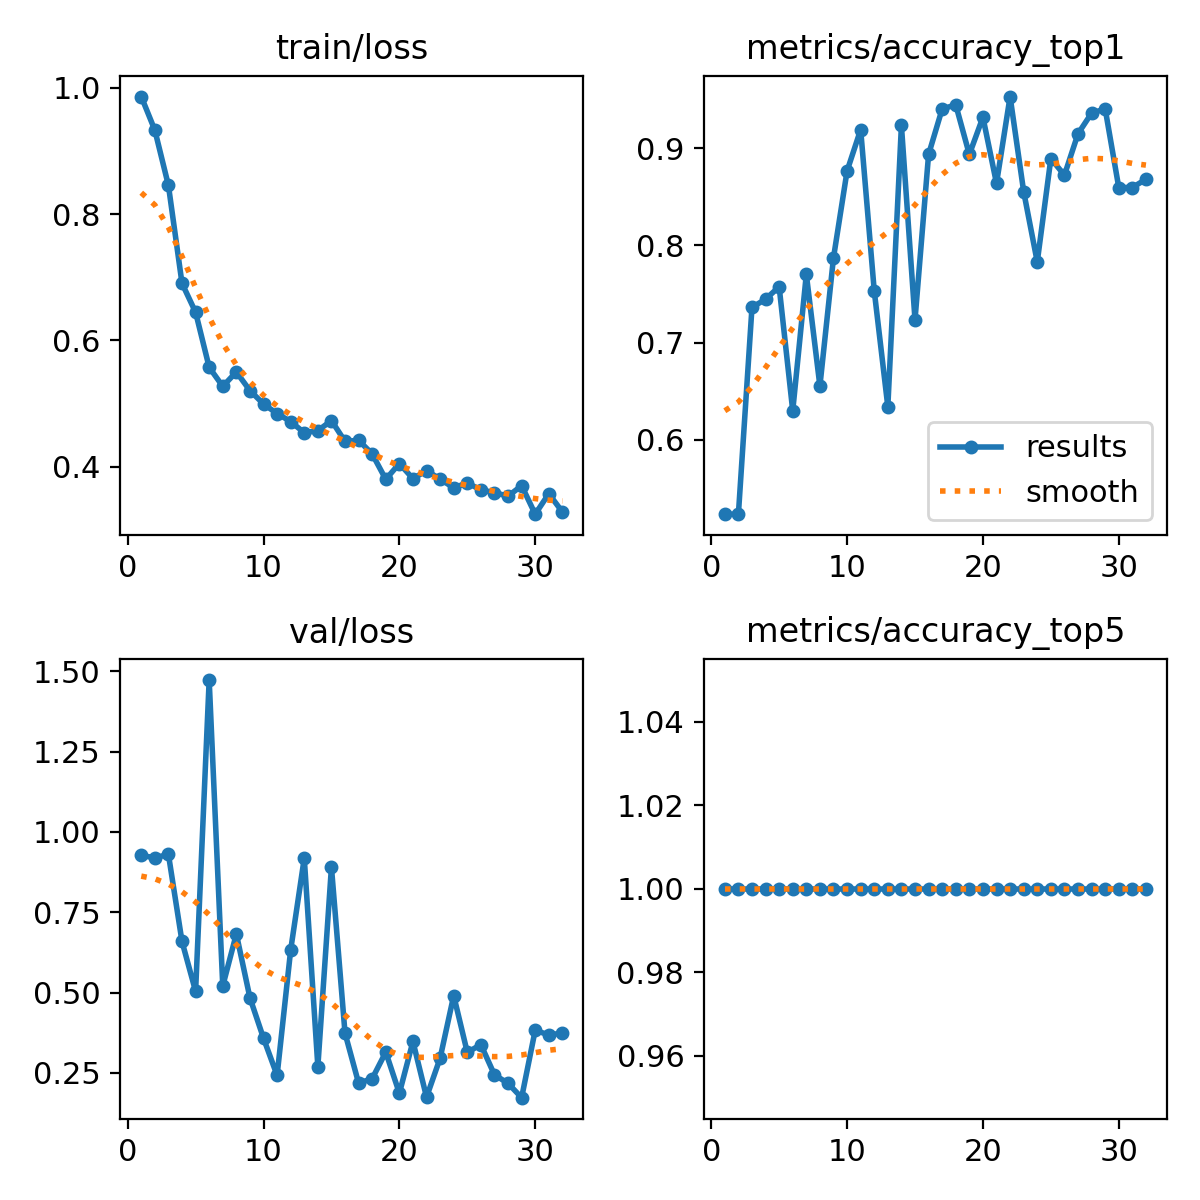

In [12]:
# Tampilkan grafik training (loss & accuracy)
from IPython.display import Image as IPImage

results_img = '/content/runs/classify/yolov26_tomat_scratch/results.png'
if os.path.exists(results_img):
    print(' Grafik Training:')
    display(IPImage(results_img, width=900))

---
## Analisis Final: Perbandingan B5 vs B6

In [13]:
print('=' * 60)
print('       TABEL PERBANDINGAN HASIL EKSPERIMEN')
print('=' * 60)
print(f'{"Eksperimen":<35} {"Top-1 Accuracy"}')
print('-' * 60)
print(f'{"Klaim Paper B1 (ImageNet)":<35} {"71.40%"}')
print(f'{"B5: Pretrained → Data Tomat":<35} {acc_top1*100:.2f}%')
print(f'{"B6: Train From Scratch (Tomat)":<35} {acc_scratch_top1*100:.2f}%')
print('=' * 60)

print(f'''
 KESIMPULAN REPRODUCE RESULTS:

1. Model pretrained YOLO26 (klaim 71.4% di ImageNet) saat diuji
   langsung ke kelas kematangan tomat menghasilkan akurasi
   {acc_top1*100:.2f}%, jauh dari ekspektasi karena model tidak
   dilatih pada domain tomat.

2. Setelah dilatih dari nol (from scratch) menggunakan dataset
   tomat VegNet, arsitektur YOLO26 berhasil mencapai akurasi
   {acc_scratch_top1*100:.2f}%, membuktikan bahwa:
   → Arsitektur YOLO26 efektif untuk klasifikasi kematangan tomat.
   → Training domain-spesifik sangat diperlukan.
''')

       TABEL PERBANDINGAN HASIL EKSPERIMEN
Eksperimen                          Top-1 Accuracy
------------------------------------------------------------
Klaim Paper B1 (ImageNet)           71.40%
B5: Pretrained → Data Tomat         0.42%
B6: Train From Scratch (Tomat)      94.96%

 KESIMPULAN REPRODUCE RESULTS:

1. Model pretrained YOLO26 (klaim 71.4% di ImageNet) saat diuji
   langsung ke kelas kematangan tomat menghasilkan akurasi
   0.42%, jauh dari ekspektasi karena model tidak
   dilatih pada domain tomat.

2. Setelah dilatih dari nol (from scratch) menggunakan dataset
   tomat VegNet, arsitektur YOLO26 berhasil mencapai akurasi
   94.96%, membuktikan bahwa:
   → Arsitektur YOLO26 efektif untuk klasifikasi kematangan tomat.
   → Training domain-spesifik sangat diperlukan.



---
## Referensi

1. **Paper Arsitektur (B1)**:  
   Jocher, G., et al. (2026). *Ultralytics YOLO26: Unified Real-Time End-to-End Vision Models*. arXiv:2606.03748.

2. **Dataset Publik (B2)**:  
   Suryawanshi, Y., Patil, K., & Chumchu, P. (2022). VegNet: Dataset of vegetable quality images for machine learning applications. *Data in Brief*, 45, 108657. https://doi.org/10.1016/j.dib.2022.108657

3. **GitHub Repository**:  
   https://github.com/akmalmanggala/tomato-maturity-classification-yolov26